In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('crc_blood_biomarker.csv')

In [3]:
df

,Patient_ID,Age,Gender,BMI,CRC_Status,Clinical_Stage,CEA,CA19_9,CA125,CRP,...,Smoking_Status,Alcohol_Use,Previous_Polyps,NSAID_Use,Statin_Use,Metformin_Use,Diabetes,Hypertension,IBD,Obesity
0,CRC_00001,63,Male,25.81,Early_CRC,Early_Stage,7.98,31.16,48.16,10.56,...,Never,NaN,Yes,No,No,No,Yes,Yes,No,No
1,CRC_00002,49,Female,33.40,Pre_Cancerous,Pre_Cancerous_Lesion,2.14,30.90,24.99,6.23,...,Never,NaN,No,No,No,No,No,No,No,Yes
2,CRC_00003,71,Female,29.48,Early_CRC,Early_Stage,13.08,26.99,47.34,11.63,...,Former,Regular,No,Yes,No,No,No,No,No,No
3,CRC_00004,45,Female,23.16,Control,No_Cancer,1.61,17.08,10.22,1.40,...,Never,Occasional,Yes,No,No,No,No,No,No,No
4,CRC_00005,49,Male,21.34,Pre_Cancerous,Pre_Cancerous_Lesion,4.99,20.24,20.13,6.47,...,Never,Regular,No,Yes,No,No,No,Yes,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,CRC_14996,61,Female,25.66,Pre_Cancerous,Pre_Cancerous_Lesion,5.25,37.74,26.33,7.50,...,Never,NaN,No,No,No,No,No,No,No,No
14996,CRC_14997,74,Female,20.95,Early_CRC,Early_Stage,4.49,34.61,35.32,9.84,...,Never,NaN,No,No,No,No,No,No,Yes,No
14997,CRC_14998,66,Male,22.39,Pre_Cancerous,Pre_Cancerous_Lesion,3.50,9.21,37.92,9.22,...,Current,NaN,No,No,No,No,No,No,No,No
14998,CRC_14999,51,Male,24.35,Control,No_Cancer,2.42,9.98,25.13,0.10,...,Never,Occasional,No,No,No,No,No,Yes,No,No


In [4]:
num_cols = df.select_dtypes(include=['number']).columns
df[num_cols] = df[num_cols].fillna(0.0)

In [5]:
df.columns = df.columns.str.lower()

In [6]:
records_values = {
    1: 'no',
    2: 'yes'
}

In [9]:
str_cols = df.select_dtypes(include=['object', 'string']).columns

In [10]:
str_cols = str_cols.str.lower()

In [13]:
str_cols = df.select_dtypes(include=['object', 'string']).columns
df[str_cols] = df[str_cols].fillna('NA')

In [15]:
for col in str_cols:
    for i in range(0, len(df)):
        if df[col].values[i] != 'NA':
            df[col].values[i] = df[col].values[i].lower()

In [19]:
df.head()

,age,gender,bmi,crc_status,clinical_stage,cea,ca19_9,ca125,crp,il6,...,smoking_status,alcohol_use,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity
0,63,male,25.81,early_crc,early_stage,7.98,31.16,48.16,10.56,6.69,...,never,NA,yes,no,no,no,yes,yes,no,no
1,49,female,33.40,pre_cancerous,pre_cancerous_lesion,2.14,30.90,24.99,6.23,2.95,...,never,NA,no,no,no,no,no,no,no,yes
2,71,female,29.48,early_crc,early_stage,13.08,26.99,47.34,11.63,5.79,...,former,regular,no,yes,no,no,no,no,no,no
3,45,female,23.16,control,no_cancer,1.61,17.08,10.22,1.40,3.92,...,never,occasional,yes,no,no,no,no,no,no,no
4,49,male,21.34,pre_cancerous,pre_cancerous_lesion,4.99,20.24,20.13,6.47,5.84,...,never,regular,no,yes,no,no,no,yes,no,no


In [17]:
df.columns = df.columns.str.lower().str.replace(' ', '')

In [18]:
del df['patient_id']

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='fecal_calprotectin', ylabel='Count'>

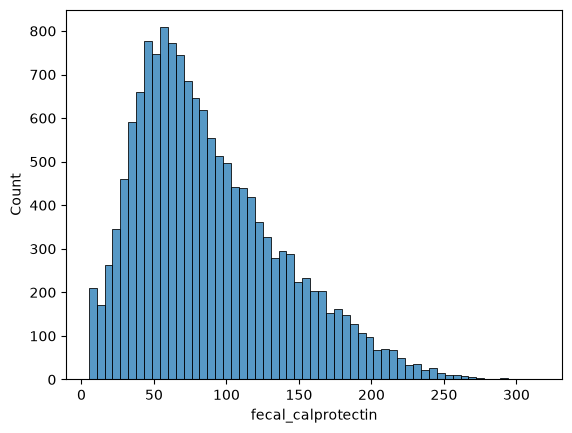

In [33]:
sns.histplot(df.fecal_calprotectin)

In [32]:
df.fecal_calprotectin

0        140.92
1         83.31
2        114.62
3         75.99
4        119.96
          ...  
14995    107.53
14996    137.75
14997     97.55
14998     16.22
14999    110.87
Name: fecal_calprotectin, Length: 15000, dtype: float64

In [34]:
map_crc_status = {'control':0, 'pre_cancerous':1, 'early_crc':2}

In [35]:
df.crc_status = df.crc_status.map(map_crc_status)

In [36]:
df.head()

,age,gender,bmi,crc_status,clinical_stage,cea,ca19_9,ca125,crp,il6,...,smoking_status,alcohol_use,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity
0,63,male,25.81,2,early_stage,7.98,31.16,48.16,10.56,6.69,...,never,NA,yes,no,no,no,yes,yes,no,no
1,49,female,33.40,1,pre_cancerous_lesion,2.14,30.90,24.99,6.23,2.95,...,never,NA,no,no,no,no,no,no,no,yes
2,71,female,29.48,2,early_stage,13.08,26.99,47.34,11.63,5.79,...,former,regular,no,yes,no,no,no,no,no,no
3,45,female,23.16,0,no_cancer,1.61,17.08,10.22,1.40,3.92,...,never,occasional,yes,no,no,no,no,no,no,no
4,49,male,21.34,1,pre_cancerous_lesion,4.99,20.24,20.13,6.47,5.84,...,never,regular,no,yes,no,no,no,yes,no,no


In [37]:
from sklearn.preprocessing import OrdinalEncoder

In [39]:
ordinal_enc = OrdinalEncoder(
    categories=[['no_cancer', 'pre_cancerous_lesion', 'early_stage']]
)

In [44]:
df['clinical_stage_encoded'] = ordinal_enc.fit_transform(df[['clinical_stage']]).astype(int)

In [45]:
df.head()

,age,gender,bmi,crc_status,clinical_stage,cea,ca19_9,ca125,crp,il6,...,alcohol_use,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage_encoded
0,63,male,25.81,2,early_stage,7.98,31.16,48.16,10.56,6.69,...,NA,yes,no,no,no,yes,yes,no,no,2
1,49,female,33.40,1,pre_cancerous_lesion,2.14,30.90,24.99,6.23,2.95,...,NA,no,no,no,no,no,no,no,yes,1
2,71,female,29.48,2,early_stage,13.08,26.99,47.34,11.63,5.79,...,regular,no,yes,no,no,no,no,no,no,2
3,45,female,23.16,0,no_cancer,1.61,17.08,10.22,1.40,3.92,...,occasional,yes,no,no,no,no,no,no,no,0
4,49,male,21.34,1,pre_cancerous_lesion,4.99,20.24,20.13,6.47,5.84,...,regular,no,yes,no,no,no,yes,no,no,1


In [46]:
df['crc_status_encoded'] = df['crc_status']

In [47]:
df.head()

,age,gender,bmi,crc_status,clinical_stage,cea,ca19_9,ca125,crp,il6,...,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage_encoded,crc_status_encoded
0,63,male,25.81,2,early_stage,7.98,31.16,48.16,10.56,6.69,...,yes,no,no,no,yes,yes,no,no,2,2
1,49,female,33.40,1,pre_cancerous_lesion,2.14,30.90,24.99,6.23,2.95,...,no,no,no,no,no,no,no,yes,1,1
2,71,female,29.48,2,early_stage,13.08,26.99,47.34,11.63,5.79,...,no,yes,no,no,no,no,no,no,2,2
3,45,female,23.16,0,no_cancer,1.61,17.08,10.22,1.40,3.92,...,yes,no,no,no,no,no,no,no,0,0
4,49,male,21.34,1,pre_cancerous_lesion,4.99,20.24,20.13,6.47,5.84,...,no,yes,no,no,no,yes,no,no,1,1


In [51]:
del df['clinical_stage']

In [52]:
df.head()

,age,gender,bmi,cea,ca19_9,ca125,crp,il6,tnf_alpha,fecal_calprotectin,...,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage_encoded,crc_status_encoded
0,63,male,25.81,7.98,31.16,48.16,10.56,6.69,11.89,140.92,...,yes,no,no,no,yes,yes,no,no,2,2
1,49,female,33.40,2.14,30.90,24.99,6.23,2.95,6.43,83.31,...,no,no,no,no,no,no,no,yes,1,1
2,71,female,29.48,13.08,26.99,47.34,11.63,5.79,10.17,114.62,...,no,yes,no,no,no,no,no,no,2,2
3,45,female,23.16,1.61,17.08,10.22,1.40,3.92,4.65,75.99,...,yes,no,no,no,no,no,no,no,0,0
4,49,male,21.34,4.99,20.24,20.13,6.47,5.84,6.11,119.96,...,no,yes,no,no,no,yes,no,no,1,1


In [53]:
df = df.rename(columns={'clinical_stage_encoded': 'clinical_stage', 'crc_status_encoded': 'crc_status'})

In [54]:
df.head()

,age,gender,bmi,cea,ca19_9,ca125,crp,il6,tnf_alpha,fecal_calprotectin,...,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage,crc_status
0,63,male,25.81,7.98,31.16,48.16,10.56,6.69,11.89,140.92,...,yes,no,no,no,yes,yes,no,no,2,2
1,49,female,33.40,2.14,30.90,24.99,6.23,2.95,6.43,83.31,...,no,no,no,no,no,no,no,yes,1,1
2,71,female,29.48,13.08,26.99,47.34,11.63,5.79,10.17,114.62,...,no,yes,no,no,no,no,no,no,2,2
3,45,female,23.16,1.61,17.08,10.22,1.40,3.92,4.65,75.99,...,yes,no,no,no,no,no,no,no,0,0
4,49,male,21.34,4.99,20.24,20.13,6.47,5.84,6.11,119.96,...,no,yes,no,no,no,yes,no,no,1,1


In [57]:
df.describe().round()

,age,bmi,cea,ca19_9,ca125,crp,il6,tnf_alpha,fecal_calprotectin,hemoglobin,...,alt,alp,creatinine,egfr,esr,fibrinogen,nlr,plr,clinical_stage,crc_status
count,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,...,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0,15000.0
mean,55.0,27.0,5.0,24.0,25.0,5.0,6.0,6.0,88.0,13.0,...,29.0,81.0,1.0,85.0,21.0,357.0,3.0,166.0,1.0,1.0
std,11.0,4.0,3.0,13.0,10.0,4.0,3.0,3.0,50.0,2.0,...,10.0,23.0,0.0,15.0,12.0,84.0,2.0,104.0,1.0,1.0
min,18.0,16.0,0.0,2.0,5.0,0.0,0.0,0.0,5.0,7.0,...,8.0,25.0,0.0,25.0,1.0,150.0,0.0,32.0,0.0,0.0
25%,48.0,24.0,2.0,15.0,18.0,2.0,3.0,4.0,51.0,12.0,...,22.0,65.0,1.0,75.0,12.0,298.0,2.0,109.0,0.0,0.0
50%,55.0,27.0,4.0,21.0,24.0,4.0,5.0,6.0,78.0,13.0,...,28.0,80.0,1.0,86.0,19.0,351.0,2.0,141.0,1.0,1.0
75%,63.0,29.0,6.0,32.0,31.0,7.0,8.0,8.0,118.0,14.0,...,35.0,95.0,1.0,95.0,28.0,410.0,3.0,189.0,2.0,2.0
max,85.0,40.0,16.0,82.0,72.0,23.0,19.0,17.0,316.0,18.0,...,75.0,191.0,2.0,130.0,78.0,700.0,29.0,1460.0,2.0,2.0


In [102]:
df.head().T

,0,1,2,3,4
age,63,49,71,45,49
gender,male,female,female,female,male
bmi,25.81,33.4,29.48,23.16,21.34
cea,7.98,2.14,13.08,1.61,4.99
ca19_9,31.16,30.9,26.99,17.08,20.24
ca125,48.16,24.99,47.34,10.22,20.13
crp,10.56,6.23,11.63,1.4,6.47
il6,6.69,2.95,5.79,3.92,5.84
tnf_alpha,11.89,6.43,10.17,4.65,6.11
fecal_calprotectin,140.92,83.31,114.62,75.99,119.96


In [95]:
df['alcohol_use'].value_counts()

alcohol_use
unknown       6260
occasional    5777
regular       2963
Name: count, dtype: int64

In [99]:
df['alcohol_use'] = df['alcohol_use'].replace('unknown', 'NaN')

In [88]:
from sklearn.model_selection import train_test_split

In [89]:
df_full_train, df_test = train_test_split(df, test_size=0.15, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.17647, random_state=1)

In [94]:
df_val

,age,gender,bmi,cea,ca19_9,ca125,crp,il6,tnf_alpha,fecal_calprotectin,...,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage,crc_status,alcohol_use_missing
0,58,male,26.46,3.44,37.24,15.15,2.90,8.89,13.22,114.34,...,no,no,no,no,no,no,no,2,2,1
1,55,male,35.34,2.97,2.86,17.02,2.67,5.16,6.40,76.56,...,no,no,yes,no,no,no,yes,1,1,0
2,59,female,27.78,6.78,36.56,22.98,1.86,6.37,4.27,106.61,...,no,yes,yes,no,no,no,no,1,1,1
3,25,female,23.33,1.26,7.94,22.12,0.54,2.88,5.33,61.08,...,no,no,no,no,yes,no,no,0,0,0
4,60,female,25.76,8.55,16.93,26.37,15.19,5.82,11.01,166.68,...,yes,yes,no,no,no,no,no,2,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2245,71,male,24.72,1.97,21.82,13.65,2.10,3.22,3.28,21.19,...,no,no,no,yes,no,no,no,0,0,1
2246,60,female,25.01,2.07,17.19,12.80,3.33,1.23,5.18,71.17,...,no,no,no,no,no,no,no,0,0,1
2247,62,female,23.89,4.22,35.45,22.02,6.00,7.16,10.01,93.72,...,no,no,no,no,no,no,no,2,2,0
2248,38,female,22.87,3.14,21.92,8.74,3.77,2.50,3.64,5.00,...,no,no,no,no,no,no,no,0,0,0


In [93]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [97]:
del df['alcohol_use_missing']

In [104]:
df['alcohol_use'] = df['alcohol_use'].map({'occasional': 0, 'regular': 1})

In [106]:
df['crc_status'].isna().sum()

np.int64(0)